# 09 — KU Leuven external validation

This notebook documents the external real-world academic-risk evaluation. The authorised KU Leuven **Open Data, Private Learners** release is kept separate from the synthetic Indian-university planner data. The experiment uses only LMS activity observed by a 30-, 60-, or 90-day cutoff. Final outcomes are labels, not predictors.

The temporal protocol is 1819 for training, 1920 for validation, and 2021 as a locked test cohort. The complete data provenance, source licence, raw-column dictionary, cleaning decisions, feature rationale, limitations, and measured confusion matrices are documented in [`docs/kuleuven-external-validation.md`](../docs/kuleuven-external-validation.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

repo_root = Path.cwd()
if not (repo_root / 'models').exists():
    repo_root = repo_root.parent
metrics_path = repo_root / 'models/metrics/kuleuven_external_metrics.json'
metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
rows = []
for cutoff, evaluation in metrics['evaluations'].items():
    for model, values in evaluation['models'].items():
        rows.append({
            'cutoff_days': int(cutoff),
            'model': model,
            'validation_pr_auc': values['validation_pr_auc'],
            'test_roc_auc': values['roc_auc'],
            'test_pr_auc': values['pr_auc'],
            'balanced_accuracy': values['balanced_accuracy'],
            'f1': values['f1'],
            'confusion_matrix': values['confusion_matrix'],
        })
comparison = pd.DataFrame(rows).sort_values(['cutoff_days', 'validation_pr_auc'], ascending=[True, False])
comparison.drop(columns='confusion_matrix').round(4)

,cutoff_days,model,validation_pr_auc,test_roc_auc,test_pr_auc,balanced_accuracy,f1
0,30,logistic_regression,0.4406,0.6754,0.5408,0.5907,0.3755
2,30,extra_trees,0.4029,0.6249,0.5100,0.5460,0.2279
1,30,random_forest,0.4025,0.6130,0.5043,0.5405,0.2039
3,30,hist_gradient_boosting,0.3570,0.6392,0.5112,0.5425,0.2098
4,60,logistic_regression,0.5278,0.6986,0.5664,0.6247,0.4677
7,60,hist_gradient_boosting,0.4803,0.6785,0.5403,0.5582,0.2637
6,60,extra_trees,0.4764,0.6576,0.5365,0.5818,0.3318
5,60,random_forest,0.4622,0.6528,0.5356,0.5677,0.2940
8,90,logistic_regression,0.5576,0.7207,0.6057,0.6433,0.5089
10,90,extra_trees,0.5081,0.7166,0.5879,0.5922,0.3569


## Formal interpretation of the comparison

Validation PR-AUC is the primary selection statistic because the planner is intended to screen for a risk class and false alerts consume finite support capacity. Test metrics are shown only after the model has been selected on the earlier validation year. Accuracy is not used as the primary criterion because it can conceal missed risky learners when the classes are imbalanced. Later cutoffs can improve discrimination because they contain more observed activity, but they also leave less time for intervention; therefore, a larger score does not automatically imply a better operational policy.

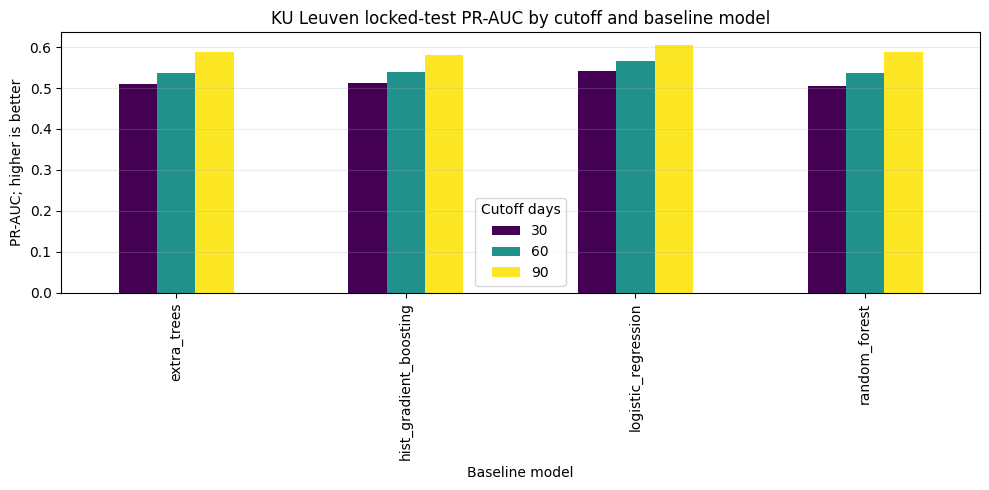

In [2]:
pivot = comparison.pivot(index='model', columns='cutoff_days', values='test_pr_auc')
ax = pivot.plot(kind='bar', figsize=(10, 5), colormap='viridis')
ax.set_title('KU Leuven locked-test PR-AUC by cutoff and baseline model')
ax.set_xlabel('Baseline model')
ax.set_ylabel('PR-AUC; higher is better')
ax.legend(title='Cutoff days')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## Confusion matrices for the selected models

Each matrix is `[[TN, FP], [FN, TP]]` on the locked 2021 test cohort. False negatives are risky learners not identified by the selected operating threshold; false positives are learners who would receive unnecessary attention. These matrices are included because a single aggregate score does not show the support-workload and missed-risk trade-off.

C:\Users\RAFISO~1\AppData\Local\Temp\ipykernel_49648\3811331930.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


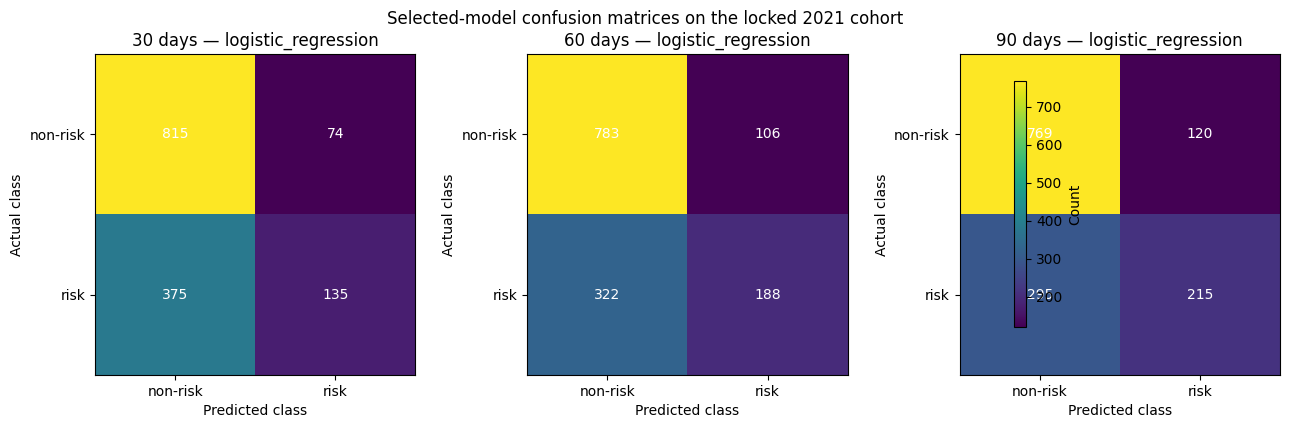

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (cutoff, evaluation) in zip(axes, sorted(metrics['evaluations'].items(), key=lambda item: int(item[0]))):
    best = evaluation['best_model']
    matrix = evaluation['models'][best]['confusion_matrix']
    image = ax.imshow(matrix, cmap='viridis')
    ax.set_title(f'{cutoff} days — {best}')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
    ax.set_xticks([0, 1], ['non-risk', 'risk'])
    ax.set_yticks([0, 1], ['non-risk', 'risk'])
    for row in range(2):
        for col in range(2):
            ax.text(col, row, matrix[row][col], ha='center', va='center', color='white')
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8, label='Count')
fig.suptitle('Selected-model confusion matrices on the locked 2021 cohort')
plt.tight_layout()
plt.show()

In [4]:
for cutoff, evaluation in sorted(metrics['evaluations'].items(), key=lambda item: int(item[0])):
    selected = evaluation['models'][evaluation['best_model']]
    print(
        f"{cutoff}-day cutoff: selected={evaluation['best_model']}; "
        f"test ROC-AUC={selected['roc_auc']:.4f}; "
        f"test PR-AUC={selected['pr_auc']:.4f}; "
        f"balanced accuracy={selected['balanced_accuracy']:.4f}; "
        f"F1={selected['f1']:.4f}"
    )

print('Reproduce the measured output with:')
print('python -m pipeline.kuleuven_external_validation --data-path data/raw/external/kuleuven/dataset.zip --metrics-output models/metrics/kuleuven_external_metrics.json --cutoffs-days 30 60 90')

30-day cutoff: selected=logistic_regression; test ROC-AUC=0.6754; test PR-AUC=0.5408; balanced accuracy=0.5907; F1=0.3755
60-day cutoff: selected=logistic_regression; test ROC-AUC=0.6986; test PR-AUC=0.5664; balanced accuracy=0.6247; F1=0.4677
90-day cutoff: selected=logistic_regression; test ROC-AUC=0.7207; test PR-AUC=0.6057; balanced accuracy=0.6433; F1=0.5089
Reproduce the measured output with:
python -m pipeline.kuleuven_external_validation --data-path data/raw/external/kuleuven/dataset.zip --metrics-output models/metrics/kuleuven_external_metrics.json --cutoffs-days 30 60 90
